In [ ]:
'''
Outliers are handled using clip function
Trend is cycle level growth
Seasonality refers to cycle level repeating pattern
ETS decompositition - Error, trend and seasonality decomposition. We can seperate trand from seasonality through time series
    2 ways to do it:
        additive: Y(t)= b(t)[trend]+s(t)[seasonality]+e(t)[residual] 
        multiplicative: Y(t)= b(t)[trend]*s(t)[seasonality]*e(t)[residual] 

for additive, e(t)=y(t)-y'(t) where Y'=b(t)+s(t)
    if there is a pattern in e(t), we can further break it down into trend and seasonality, to increase accuracy
    NESTED FORECAST - however, if errors are distributed normally and close to 0, we can say that neither underforecasting and nor  overforecasting

Trend Caluculation:
    movinng average of a full season
        SMA - Simple moving average: n observations from t-1 till t-n
        cma - central moving average: n observations from t-n/2 till t+n/2
        wma - Weighted moving average: more weight to recent stamps
            w(m)=(a1*y(t-1)+a2*y(t-2)----an*y(t-n))/(a1+a2+---an)

We cant use random train-test split. We have to make train and test sequential.
    In the below example, we are training on 17 years of data and keepoing last 1 year of data for test

Simple naive models
    1- simple mean or median model
    2- seasonal naive forecast - cipying exact same cyclical values from historical data


'''

In [91]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\16_ml_unsupervised_and_recsys\16.2_time_seties_analysis_1\mobilesales.csv')

# Handling nulls and outliers

## Nulls

<Axes: >

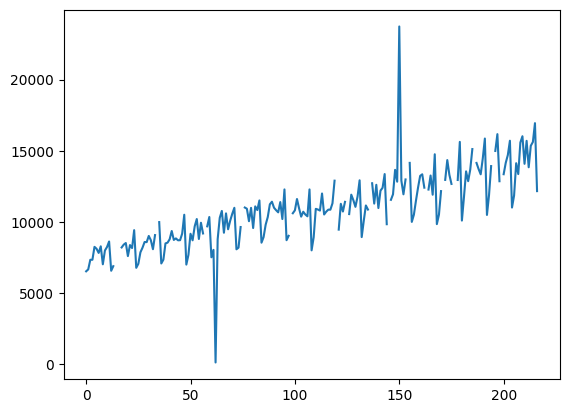

In [92]:
df.Sales.plot()
# We can see multiple  nulls and 2 outliers

In [93]:
df['Sales'].isnull().sum()

np.int64(19)

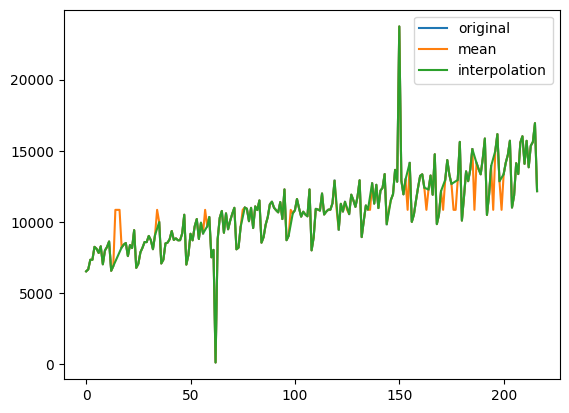

In [94]:
# Comparing 3 ways of handling nulls: no handling, mean and linear interpolation

df['Sales_2']=df['Sales'].fillna(np.mean(df['Sales']))
df['Sales_3']=df['Sales'].interpolate(method='linear')

df.Sales.plot(label='original')
df.Sales_2.plot(label='mean')
df.Sales_3.plot(label='interpolation')
plt.legend()



## Outliers

<Axes: >

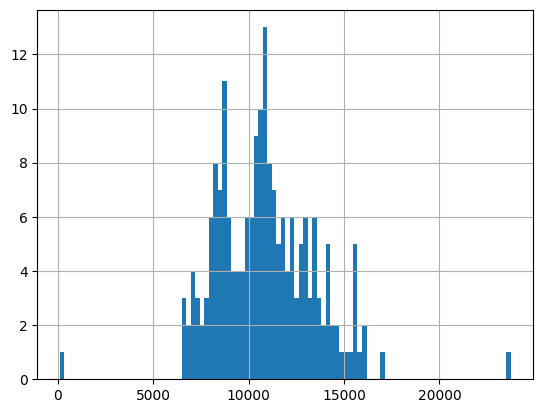

In [95]:
df.Sales.hist(bins=100)

# We can see 2 primary outliers

In [96]:
# Using clip function
df['Sales_4']=df['Sales_3'].clip(upper=np.quantile(df['Sales_3'],0.95),lower=np.quantile(df['Sales_3'],0.05))

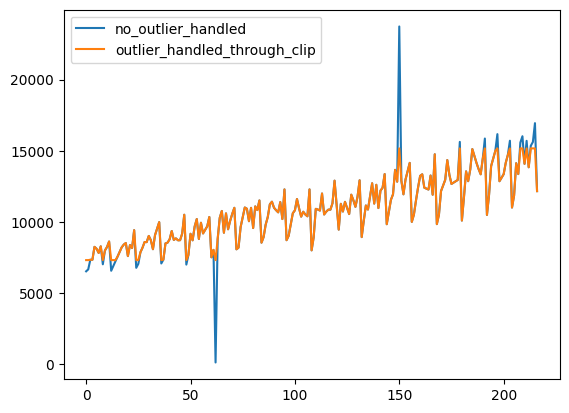

In [97]:
df['Sales_3'].plot(label='no_outlier_handled')
df.Sales_4.plot(label='outlier_handled_through_clip')
plt.legend()

# Note that 95 percentile can be an issue for the last cycle where growth is already significant

<Axes: >

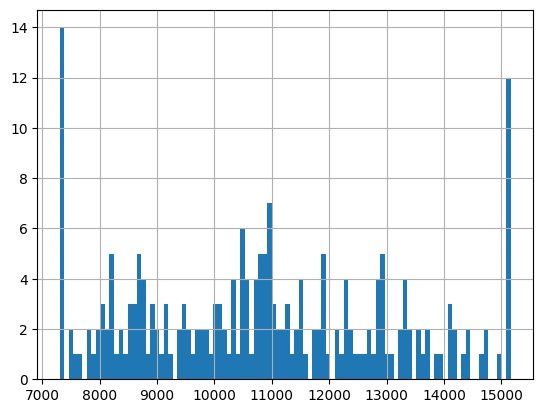

In [98]:
df.Sales_4.hist(bins=100)

# ETS Time series decomposition

## Moving Averages

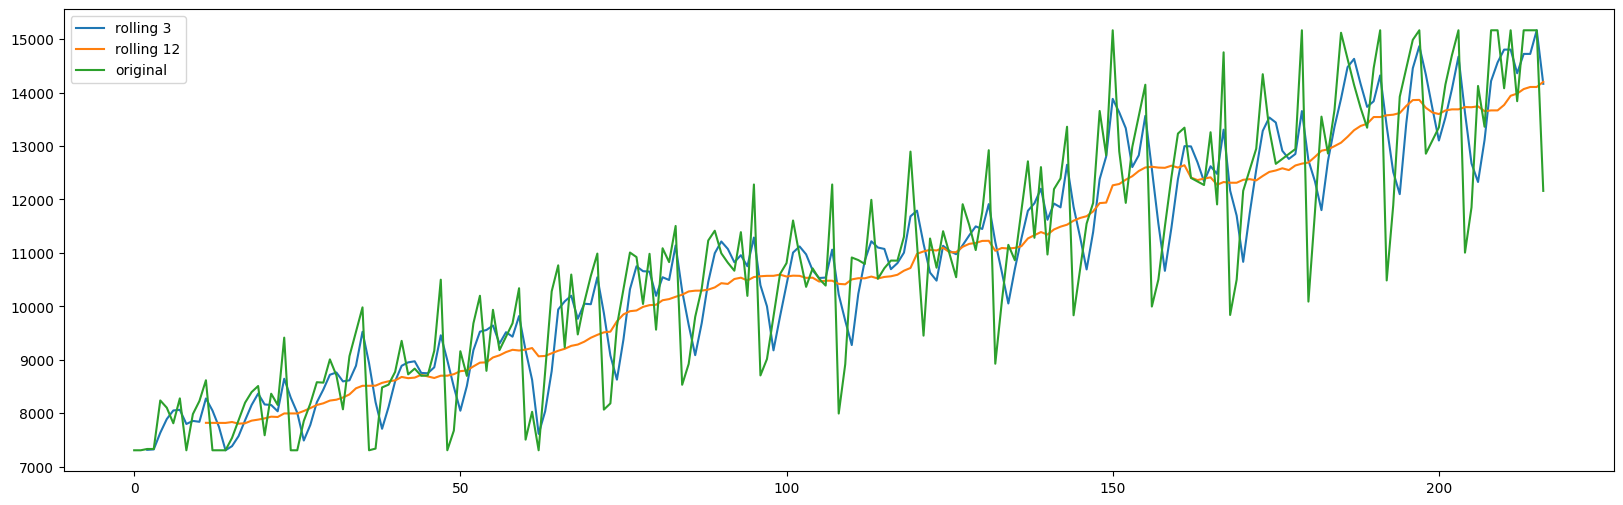

In [99]:
# No center
plt.figure(figsize=(20,6))
df['Sales_4'].rolling(window=3,center=False).mean().plot(label='rolling 3')
df['Sales_4'].rolling(window=12,center=False).mean().plot(label='rolling 12')
df['Sales_4'].plot(label='original')

plt.legend()

# Note the lag in peaks



In [100]:
# Centre = True
# We cant use this for trend for forecasting since future values are not present 



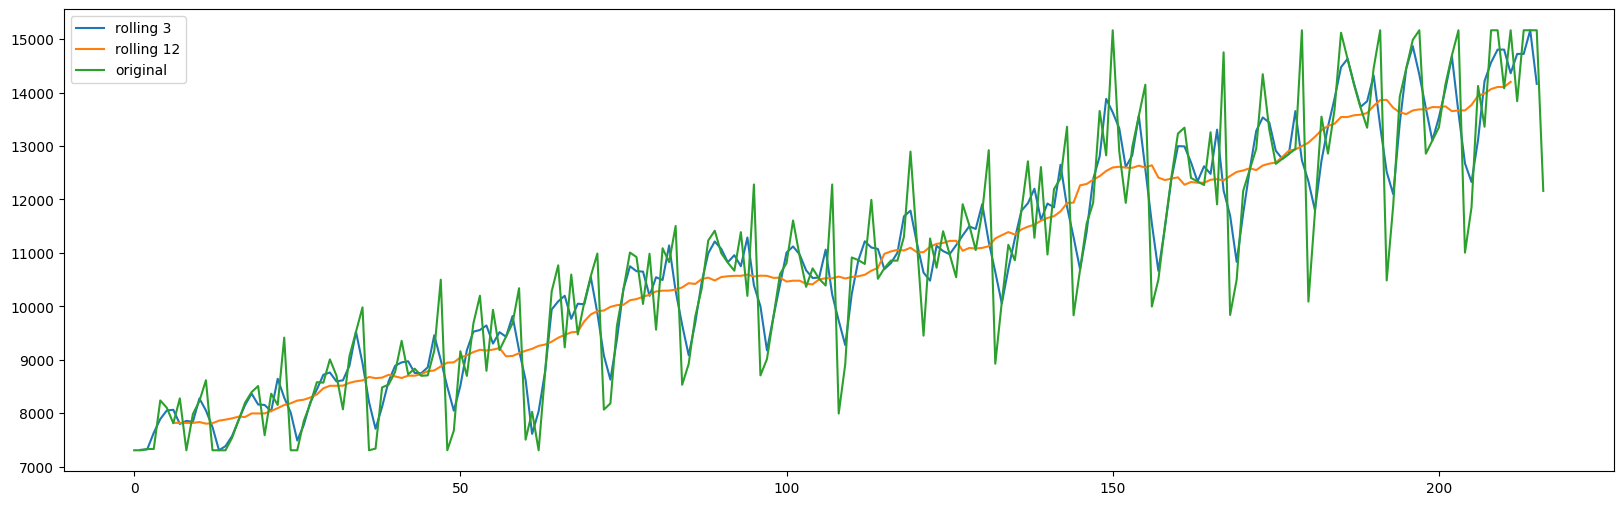

In [101]:
# No center
plt.figure(figsize=(20,6))
df['Sales_4'].rolling(window=3,center=True).mean().plot(label='rolling 3')
df['Sales_4'].rolling(window=12,center=True).mean().plot(label='rolling 12')
df['Sales_4'].plot(label='original')

plt.legend()

# Note the lag in peaks



# ETS decomposition using stats model

In [102]:
import statsmodels.api as sm

In [103]:
model=sm.tsa.seasonal_decompose(df['Sales_4'],period=12,model="additive")

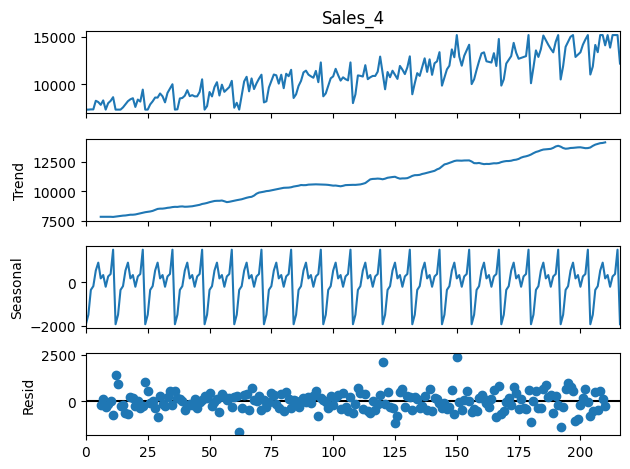

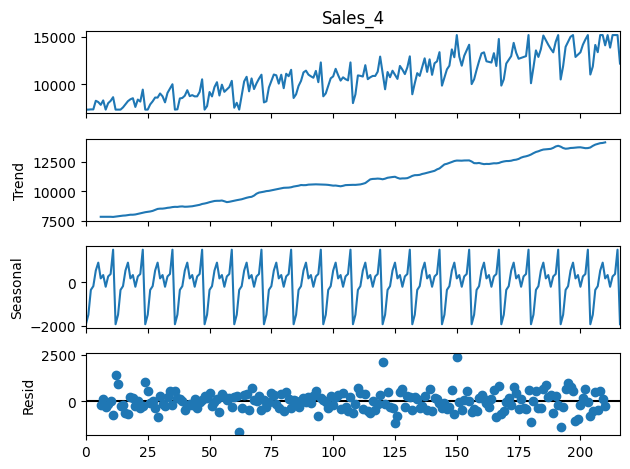

In [104]:
model.plot()

# 1 - actual plot
# 2 - trend
# 3 - Seasonality
# 4 - Error

<Axes: >

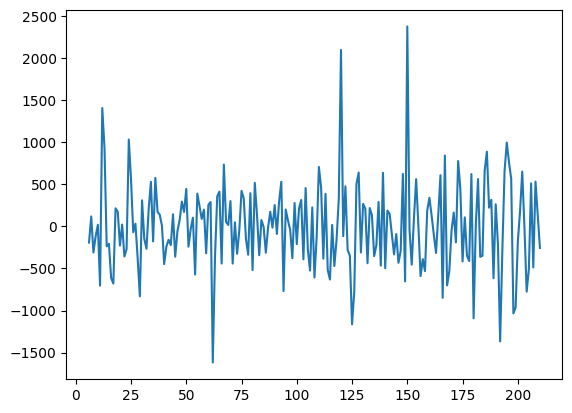

In [105]:
model.resid.plot()

# Decomposition from scratch

In [106]:
df['trend']=df['Sales_4'].rolling(window=12,center=True).mean()

In [107]:
df['seasonality']=df['Sales_4']-df['trend']

<Axes: >

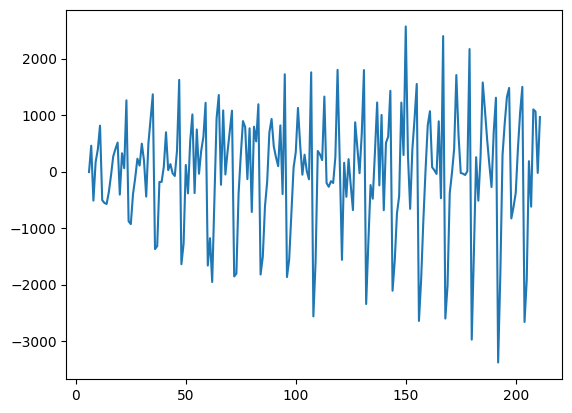

In [108]:
df['seasonality'].plot()

# Generating forecasts

## Train test splits

In [109]:
# with 18 years of data, we want to keep test data for 12 months data

df_test=df[-12:]
df_train=df[:(df.shape[0]-12)]

## Simple forecasts method

In [110]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,mean_absolute_percentage_error

### 1.mean method

In [111]:
df_test['pred']=df_train['Sales_4'].mean()

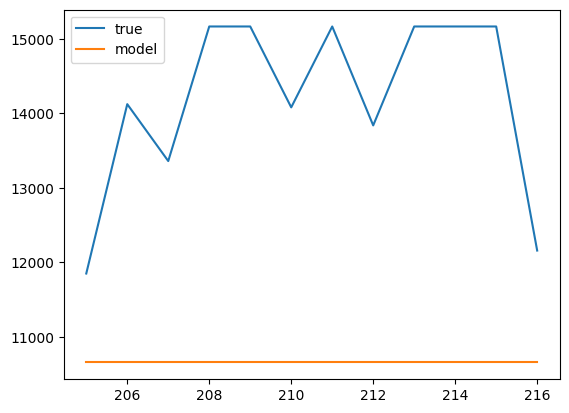

In [112]:
df_test['Sales_4'].plot(label='true')
df_test['pred'].plot(label='model')
plt.legend()

In [113]:
print("mape is ", mean_absolute_percentage_error(df_test['Sales_4'],df_test['pred']))
print("mae is ", mean_absolute_error(df_test['Sales_4'],df_test['pred']))
print("rmse is ", root_mean_squared_error(df_test['Sales_4'],df_test['pred']))

mape is  0.2438983589435486
mae is  3540.889999999998
rmse is  3725.6903145054857


### 2.Naive model

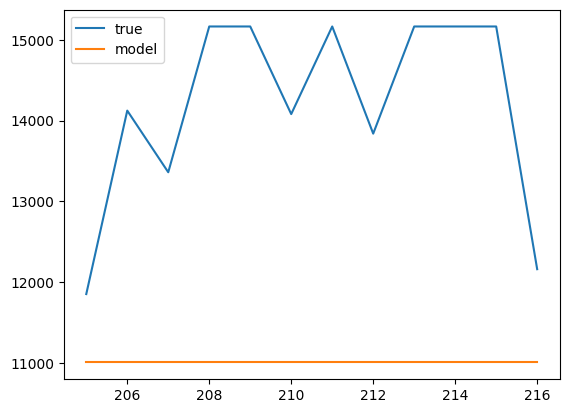

In [114]:
# just choose the last value from the train data 

df_test['pred_naive']=list(df_train['Sales_4'])[-1]

df_test['Sales_4'].plot(label='true')
df_test['pred_naive'].plot(label='model')
plt.legend()

In [115]:
print("mape is ", mean_absolute_percentage_error(df_test['Sales_4'],df_test['pred_naive']))
print("mae is ", mean_absolute_error(df_test['Sales_4'],df_test['pred_naive']))
print("rmse is ", root_mean_squared_error(df_test['Sales_4'],df_test['pred_naive']))

mape is  0.21936638911262726
mae is  3195.049999999999
rmse is  3398.707229227017


### 3.Seasonal naive forecast - same time last season

In [117]:
# df_test['pred_saesonal_naive']
# df_test
df_test=df_test.reset_index()
df_test['pred_saesonal_naive']=np.nan
for i in np.arange(df_test.shape[0]):
    df_test.loc[i, 'pred_saesonal_naive'] = list(df_train['Sales_4'])[(-12 + i)]

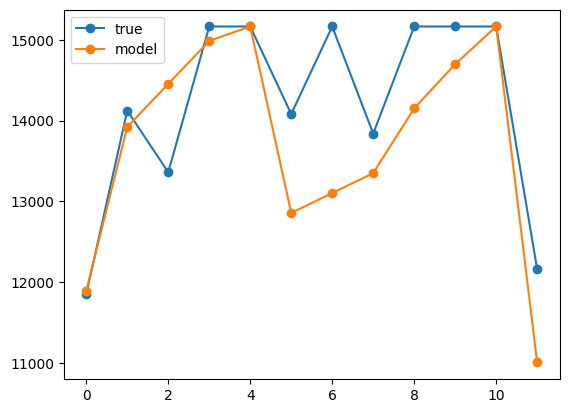

In [121]:

df_test['Sales_4'].plot(label='true',style="-o")
df_test['pred_saesonal_naive'].plot(label='model',style="-o")
plt.legend()

In [122]:
print("mape is ", mean_absolute_percentage_error(df_test['Sales_4'],df_test['pred_saesonal_naive']))
print("mae is ", mean_absolute_error(df_test['Sales_4'],df_test['pred_saesonal_naive']))
print("rmse is ", root_mean_squared_error(df_test['Sales_4'],df_test['pred_saesonal_naive']))

mape is  0.04684404895123864
mae is  660.3666666666655
rmse is  905.5694497570748


### 4.Drift method - extending slope of last and first point

In [131]:

slope=(list(df_train['Sales_4'])[-1]-list(df_train['Sales_4'])[0])/df_train.shape[0]
df_test['pred_drift']=list(df_train['Sales_4'])[-1]+slope*(np.arange(df_test.shape[0]))

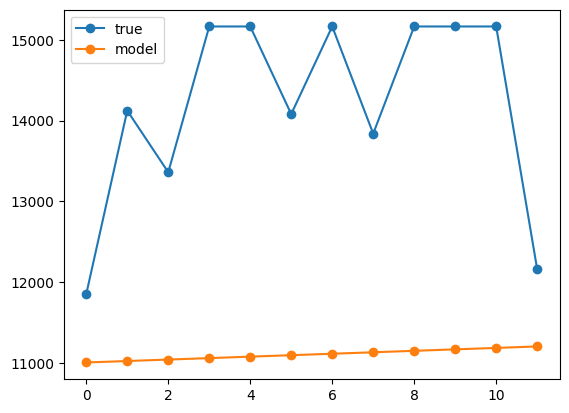

In [132]:
df_test['Sales_4'].plot(label='true',style="-o")
df_test['pred_drift'].plot(label='model',style="-o")
plt.legend()

In [133]:
print("mape is ", mean_absolute_percentage_error(df_test['Sales_4'],df_test['pred_drift']))
print("mae is ", mean_absolute_error(df_test['Sales_4'],df_test['pred_drift']))
print("rmse is ", root_mean_squared_error(df_test['Sales_4'],df_test['pred_drift']))

mape is  0.21241715379340134
mae is  3095.8568292682917
rmse is  3301.099357023592


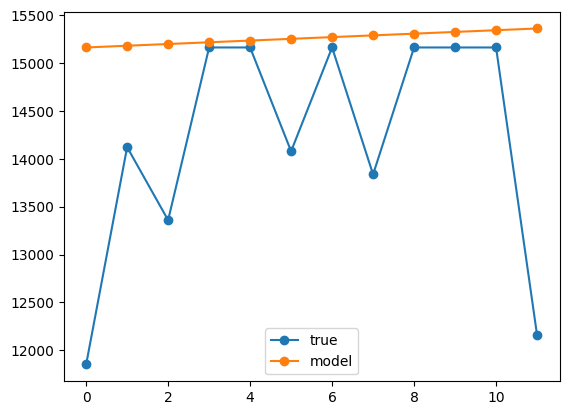

In [134]:
# this is very sensitive to the last value. just changing 2nd last from last value changes a lot of things

slope=(list(df_train['Sales_4'])[-1]-list(df_train['Sales_4'])[0])/df_train.shape[0]
df_test['pred_drift']=list(df_train['Sales_4'])[-2]+slope*(np.arange(df_test.shape[0]))

df_test['Sales_4'].plot(label='true',style="-o")
df_test['pred_drift'].plot(label='model',style="-o")
plt.legend()